# Random-variable simulation

**Gabriel Trabelsi**

Geometric, Gaussian and correlated Gaussian simulation: from distribution identities to Python implementations.

**Academic context:** UM4MA379, Statistique Computationnelle, Sorbonne Université, Master 1, 2025-2026. Course: A. Guyader; practical sessions: M. Sangnier. Implementations and completed experiments by Gabriel Trabelsi, developed within the supplied exercise framework.

Figures and outputs are retained from the original notebook. Random draws and timings may differ on a new run; historical execution counters have been cleared.

In [ ]:
import numpy as np  # Vectors and matrices
from scipy import stats  # Probability distributions
import matplotlib.pyplot as plt  # Plots
from time import perf_counter
# Enable nice plots
import matplotlib as mpl
try:
    mpl.style.use('seaborn-v0_8')
except:
    mpl.style.use('seaborn')
mpl.rcParams['image.cmap'] = 'plasma'
nice_hist = dict(bins='auto', density=True, ec='w')


## 1. Geometric sampling

Compare SciPy, repeated Bernoulli trials and a vectorized inverse-transform construction.

In [ ]:
n = 10000
p = 1/3
start = perf_counter()

sample = stats.geom(p=p).rvs(size=n)

end = perf_counter()

print(end-start)


0.0010198999661952257


In [ ]:
def Bernouilli(p):
    uniform = stats.uniform().rvs()
    return 1 if uniform<=p else 0

def Geo(p, n_iter=10000000):
    k = 0
    bern = 0
    while k <= n_iter and bern < 1:
        bern = Bernouilli(p)
        k += 1
    return k
def sample_Geo(n, p):
    return [Geo(p) for i in range(n)]

start = perf_counter()

sample = sample_Geo(n, p)

end = perf_counter()

print(end-start)


12.737161300028674


In [ ]:
uniform = stats.uniform()

def expon(lamb, n):
    unif = uniform.rvs(n)
    return -np.log(unif)/lamb

def Geo_exp(p):
    return np.ceil(expon(-np.log(1-p), 1)[0])

def sample_Geo_exp_vec(n, p):
    U = np.random.uniform(size=n)
    return np.ceil(-np.log(U) / (-np.log(1 - p)))

start = perf_counter()

sample = sample_Geo_exp_vec(n, p)

end = perf_counter()

print(end-start)


0.0004913000157102942


## 2. Box-Muller sampling

The function returns two Gaussian values per row. The original timing cell compares this with a SciPy call returning one value per row, so the timings do not compare equal output counts.

In [ ]:
n = 10**7

def box_muller(n):
    uniforms = uniform.rvs(size=n)*2*np.pi
    expo = expon(1/2, n)
    R = expo**(1/2)
    return np.column_stack((R*np.cos(uniforms), R*np.sin(uniforms)))

start = perf_counter()

box_muller(n)

end = perf_counter()

print(end-start)

start = perf_counter()

stats.norm().rvs(size=n)

end = perf_counter()

print(end-start)


0.7401760999346152
0.20161899994127452


(np.float64(-3.9826791451326926),
 np.float64(3.9504554707877233),
 np.float64(-4.009914756404866),
 np.float64(3.9498344724527796))

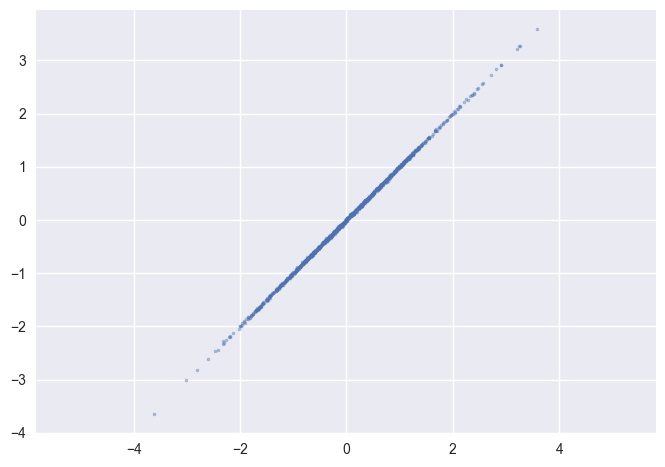

In [ ]:
def multivariate_gauss(mu, rho, n):

    sample = box_muller(n) # de shape n*2 ici, pas encore généralisée pour toute dimension
    A = np.linalg.cholesky(rho)

    return sample @ A.T + mu

rho = np.array([[1.0, 0.9999],
                [0.9999, 1.0]])      # Strongly correlated, positive-definite covariance.

mu = np.array([0,0])

sample = multivariate_gauss(mu, rho, 1000)

x = np.linspace(-6, 6)
y = np.linspace(-6, 6)

xx, yy= np.meshgrid(x, y)

plt.scatter(sample[:, 0], sample[:, 1], s=5, alpha=0.4)
plt.axis('equal')


## 3. Marsaglia polar sampling

Rejection inside the unit disk is followed by a radial transformation.

In [ ]:
def rejet_wz():
    prop = uniform.rvs(size=2)*2-1
    while (prop**2).sum() > 1:
        prop = uniform.rvs(size=2)*2-1
    return np.array(prop)


In [ ]:
def marsaglia(n):
    wz = np.array([rejet_wz() for _ in range(n)])
    S = (wz**2).sum(axis=1)
    cos_sin = wz / (S**(1/2))[:, None] #broadcast  en [n, 2] / [n, 1] = [n, 2] ou cos_sin[i,j] = wz[i,j]/ s[i] soit la ligne i est (Wz(i,j)/s[i], )
    return cos_sin * np.sqrt((-2*np.log(S)))[:, None]

start = perf_counter()
marsaglia(10**4)
end = perf_counter()
print(end-start)

out = marsaglia(100000)
print(out.mean(axis=0))             # ~ [0, 0]
print(out.std(axis=0))              # ~ [1, 1]
print(np.corrcoef(out.T)[0, 1])     # ~ 0


0.2810703000286594
[-0.00077532  0.00046928]
[0.99943001 1.00178362]
-0.004437820192692507


## 4. Correlated Gaussian vectors

A Cholesky transform produces two-dimensional correlated samples. The final figure overlays simulated points and the theoretical density.

(np.float64(-3.539893708480883),
 np.float64(3.058491133291642),
 np.float64(-3.8572001460914422),
 np.float64(4.145087705982723))

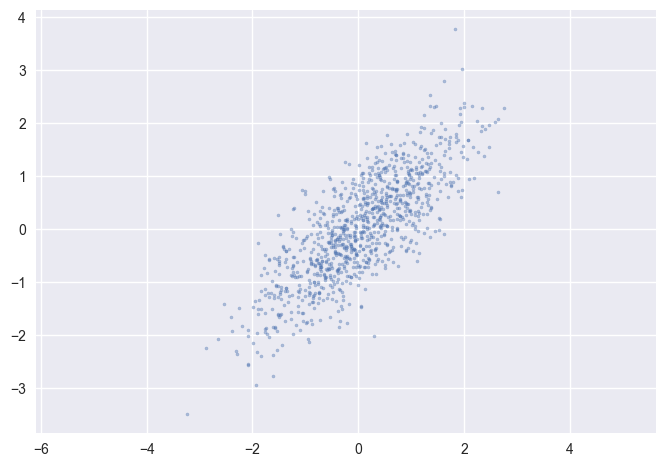

In [ ]:
def multivariate_gauss(mu, rho, n):

    sample = box_muller(n) # de shape n*2 ici, pas encore généralisée pour toute dimension
    A = np.linalg.cholesky(rho)

    return sample @ A.T + mu

rho = np.array([[1.0, 0.8],
                [0.8, 1.0]])      # det = 1 - 0.64 = 0.36 > 0

mu = np.array([0,0])

sample = multivariate_gauss(mu, rho, 1000)

x = np.linspace(-6, 6)
y = np.linspace(-6, 6)

xx, yy= np.meshgrid(x, y)

plt.scatter(sample[:, 0], sample[:, 1], s=5, alpha=0.4)
plt.axis('equal')


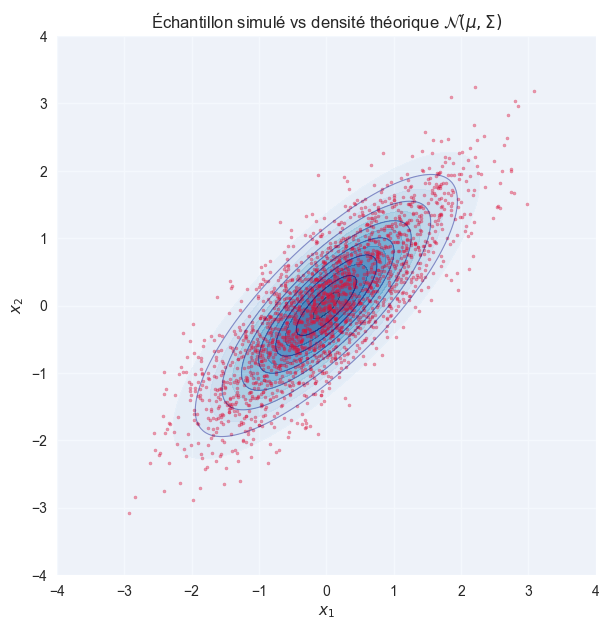

In [ ]:
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt
import numpy as np

# 1. Paramètres du modèle
mu = np.array([0.0, 0.0])
Sigma = np.array([[1.0, 0.8],
                  [0.8, 1.0]])

# 2. Échantillon simulé
sample = multivariate_gauss(mu, Sigma, n=2000)         # (n, 2)

# 3. Grille pour la densité théorique
x = np.linspace(-4, 4, 200)
y = np.linspace(-4, 4, 200)
xx, yy = np.meshgrid(x, y)
grille = np.dstack((xx, yy))                           # shape (200, 200, 2)
Z = multivariate_normal(mu, Sigma).pdf(grille)         # shape (200, 200)

# 4. Superposition contour théorique + nuage empirique
fig, ax = plt.subplots(figsize=(7, 7))
ax.contourf(xx, yy, Z, levels=15, cmap='Blues', alpha=0.7)
ax.contour(xx, yy, Z, levels=6, colors='navy', alpha=0.4, linewidths=0.8)
ax.scatter(sample[:, 0], sample[:, 1], s=5, color='crimson', alpha=0.4)
ax.set_aspect('equal')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title(r'Échantillon simulé vs densité théorique $\mathcal{N}(\mu, \Sigma)$')
plt.show()


## Notes

The unused scalar `Geo_exp` helper now passes the sample-size argument required by `expon`; the vectorized experiment and its saved output are unchanged. Sampling sizes and original timing results are retained. The geometric loop has a finite guard, so it should not be used as an exact simulator for arbitrarily small success probabilities.